In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Paste your Kaggle API token here: ")
print("Kaggle API token loaded securely for this session.")

Paste your Kaggle API token here: ··········
Kaggle API token loaded securely for this session.


In [ ]:
!pip -q install kaggle

import os
from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()

print("Kaggle API authentication successful!")

Kaggle API authentication successful!


In [ ]:
import os
from pathlib import Path

DATA_DIR = Path("/content/fruit_fresh_rotten")

DATA_DIR.mkdir(parents=True, exist_ok=True)

!kaggle datasets download -d sriramr/fruits-fresh-and-rotten-for-classification -p /content/fruit_fresh_rotten --unzip

print("Dataset download/extraction command finished.")
print("Files in dataset folder:", os.listdir(DATA_DIR))

Dataset URL: https://www.kaggle.com/datasets/sriramr/fruits-fresh-and-rotten-for-classification
License(s): unknown
100% 3.58G/3.58G [00:38<00:00, 99.5MB/s]

Dataset download/extraction command finished.
Files in dataset folder: ['dataset']


In [ ]:
from pathlib import Path

DATA_DIR = Path("/content/fruit_fresh_rotten")

for path in sorted(DATA_DIR.rglob("*")):
    if path.is_dir():
        print(path.relative_to(DATA_DIR))

dataset
dataset/dataset
dataset/dataset/test
dataset/dataset/test/freshapples
dataset/dataset/test/freshbanana
dataset/dataset/test/freshoranges
dataset/dataset/test/rottenapples
dataset/dataset/test/rottenbanana
dataset/dataset/test/rottenoranges
dataset/dataset/train
dataset/dataset/train/freshapples
dataset/dataset/train/freshbanana
dataset/dataset/train/freshoranges
dataset/dataset/train/rottenapples
dataset/dataset/train/rottenbanana
dataset/dataset/train/rottenoranges
dataset/test
dataset/test/freshapples
dataset/test/freshbanana
dataset/test/freshoranges
dataset/test/rottenapples
dataset/test/rottenbanana
dataset/test/rottenoranges
dataset/train
dataset/train/freshapples
dataset/train/freshbanana
dataset/train/freshoranges
dataset/train/rottenapples
dataset/train/rottenbanana
dataset/train/rottenoranges


In [ ]:
from pathlib import Path

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

for split in ["train", "test"]:
    split_dir = DATA_DIR / split

    if not split_dir.exists():
        print(f"'{split}' folder not found at {split_dir}")
        continue

    print(f"\n{split.upper()} SET")

    total = 0

    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        count = sum(
            1 for p in class_dir.rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        )
        print(f"{class_dir.name}: {count}")
        total += count

    print(f"Total images: {total}")

'train' folder not found at /content/fruit_fresh_rotten/train
'test' folder not found at /content/fruit_fresh_rotten/test


In [ ]:
from pathlib import Path

DATA_DIR = Path("/content/fruit_fresh_rotten/dataset/dataset")

print("Dataset exists:", DATA_DIR.exists())
print("Train folder exists:", (DATA_DIR / "train").exists())
print("Test folder exists:", (DATA_DIR / "test").exists())

Dataset exists: True
Train folder exists: True
Test folder exists: True


In [ ]:
from pathlib import Path

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

for split in ["train", "test"]:
    split_dir = DATA_DIR / split
    print(f"\n--- {split.upper()} SET ---")

    total = 0

    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        count = sum(
            1 for p in class_dir.rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        )
        print(f"{class_dir.name}: {count}")
        total += count

    print("Total images:", total)


--- TRAIN SET ---
freshapples: 1693
freshbanana: 1581
freshoranges: 1466
rottenapples: 2342
rottenbanana: 2224
rottenoranges: 1595
Total images: 10901

--- TEST SET ---
freshapples: 395
freshbanana: 381
freshoranges: 388
rottenapples: 601
rottenbanana: 530
rottenoranges: 403
Total images: 2698


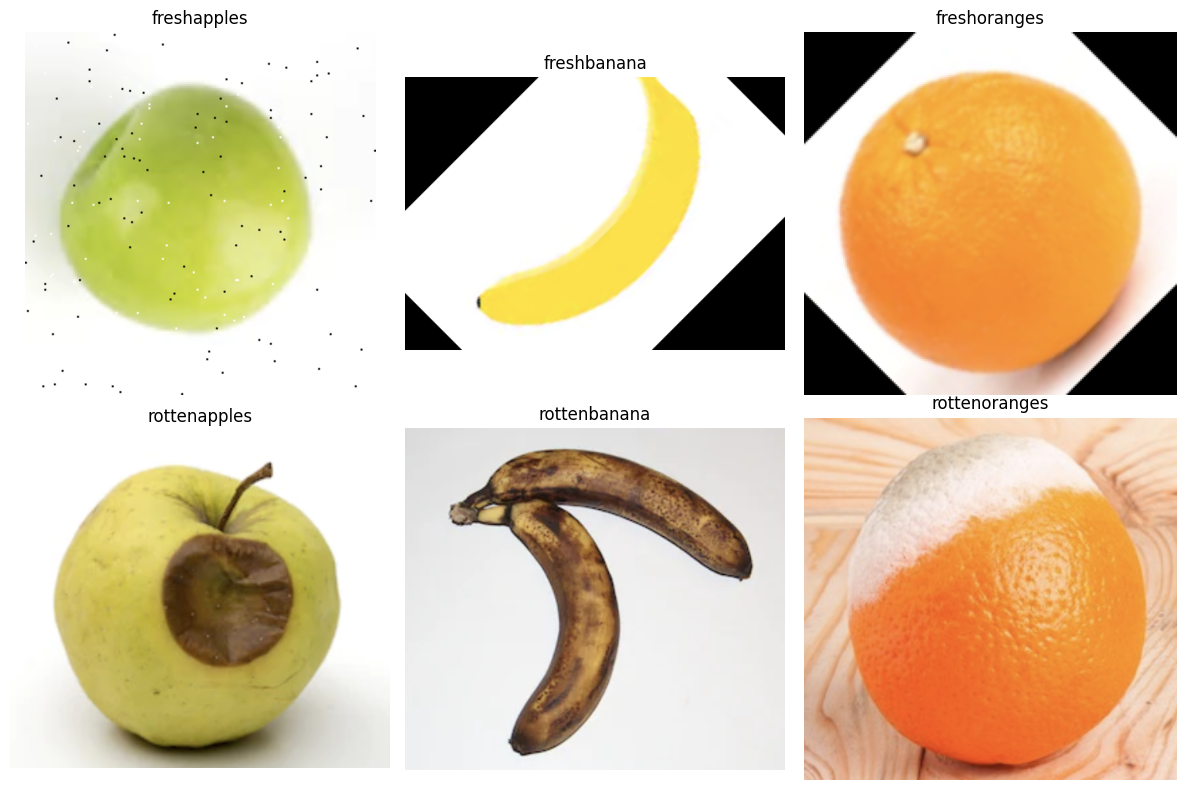

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

train_dir = DATA_DIR / "train"
class_names = sorted(
    p.name for p in train_dir.iterdir() if p.is_dir()
)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, class_name in zip(axes.flat, class_names):
    class_dir = train_dir / class_name

    image_paths = [
        p for p in class_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    image_path = random.choice(image_paths)
    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from collections import Counter
from PIL import Image

dimension_counts = Counter()
corrupt_images = []
checked = 0

for class_name in class_names:
    class_dir = train_dir / class_name

    for path in class_dir.rglob("*"):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            try:
                with Image.open(path) as img:
                    dimension_counts[img.size] += 1
                checked += 1
            except Exception:
                corrupt_images.append(str(path))

print("Readable training images checked:", checked)
print("Most common image dimensions:")
for size, count in dimension_counts.most_common(10):
    print(f"{size}: {count}")

print("Unreadable images:", len(corrupt_images))

Readable training images checked: 10901
Most common image dimensions:
(392, 360): 22
(352, 358): 18
(386, 350): 18
(374, 410): 17
(500, 452): 17
(388, 374): 17
(292, 310): 17
(334, 300): 17
(628, 374): 17
(390, 396): 16
Unreadable images: 0


In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
VALIDATION_SPLIT = 0.15

TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"

print("TensorFlow:", tf.__version__)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Validation split:", VALIDATION_SPLIT)
print("Training directory exists:", TRAIN_DIR.exists())
print("Test directory exists:", TEST_DIR.exists())

TensorFlow: 2.21.0
Image size: (224, 224)
Batch size: 32
Validation split: 0.15
Training directory exists: True
Test directory exists: True


In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    str(TRAIN_DIR),
    validation_split=VALIDATION_SPLIT,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    str(TRAIN_DIR),
    validation_split=VALIDATION_SPLIT,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    str(TEST_DIR),
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

print("\nDatasets loaded successfully.")

Found 10901 files belonging to 6 classes.
Using 9266 files for training.
Found 10901 files belonging to 6 classes.
Using 1635 files for validation.
Found 2698 files belonging to 6 classes.

Datasets loaded successfully.


In [ ]:
class_names = train_ds.class_names

print("Class names:", class_names)
print("Number of classes:", len(class_names))

images, labels = next(iter(train_ds))

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image pixel range:",
      float(tf.reduce_min(images)),
      "to",
      float(tf.reduce_max(images)))

print("\nTraining images:", len(train_ds.file_paths))
print("Validation images:", len(val_ds.file_paths))
print("Test images:", len(test_ds.file_paths))

Class names: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']
Number of classes: 6

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image pixel range: 0.0 to 255.0

Training images: 9266
Validation images: 1635
Test images: 2698


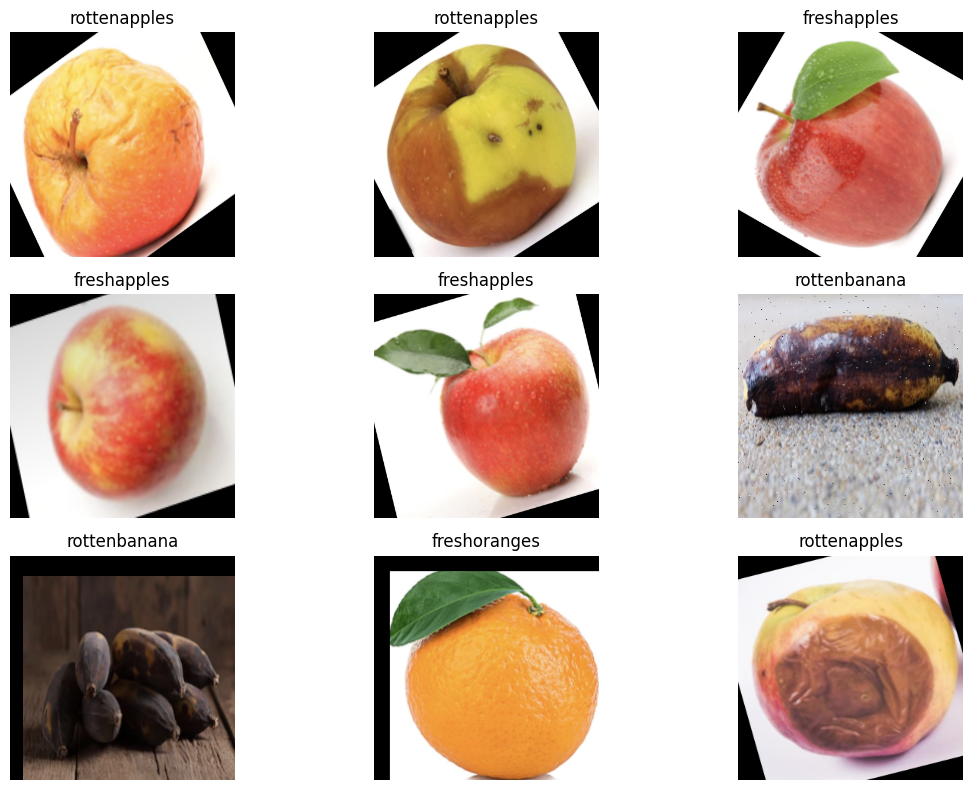

In [ ]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(tf.cast(images[i], tf.uint8).numpy())
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/FruitFresh_AI")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Checkpoint folder:", CHECKPOINT_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/FruitFresh_AI
Checkpoint folder: /content/drive/MyDrive/FruitFresh_AI/checkpoints


In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal", seed=SEED),
    tf.keras.layers.RandomRotation(0.08, seed=SEED),
    tf.keras.layers.RandomZoom(0.10, seed=SEED),
], name="data_augmentation")

print("Training augmentation configured.")

Training augmentation configured.


In [ ]:
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.25)(x)
outputs = tf.keras.layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs, name="FruitFresh_EfficientNetB0")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "FruitFresh_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,057,257 (15.48 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(CHECKPOINT_DIR / "best_head.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks
)

Epoch 1/8
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - accuracy: 0.8324 - loss: 0.5875
Epoch 1: val_loss improved from None to 0.20120, saving model to /content/drive/MyDrive/FruitFresh_AI/checkpoints/best_head.keras

Epoch 1: finished saving model to /content/drive/MyDrive/FruitFresh_AI/checkpoints/best_head.keras
290/290 ━━━━━━━━━━━━━━━━━━━━ 57s 141ms/step - accuracy: 0.9240 - loss: 0.3058 - val_accuracy: 0.9315 - val_loss: 0.2012
Epoch 2/8
289/290 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.9672 - loss: 0.1173
Epoch 2: val_loss improved from 0.20120 to 0.11521, saving model to /content/drive/MyDrive/FruitFresh_AI/checkpoints/best_head.keras

Epoch 2: finished saving model to /content/drive/MyDrive/FruitFresh_AI/checkpoints/best_head.keras
290/290 ━━━━━━━━━━━━━━━━━━━━ 79s 147ms/step - accuracy: 0.9727 - loss: 0.1028 - val_accuracy: 0.9670 - val_loss: 0.1152
Epoch 3/8
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.9819 - loss: 0.0814
Epoch 3: val_loss improved from 0.11

In [ ]:
import tensorflow as tf
from pathlib import Path

BEST_HEAD_PATH = CHECKPOINT_DIR / "best_head.keras"

print("Checkpoint exists:", BEST_HEAD_PATH.exists())
print("Model loaded:", model.name)
print("Base model:", base_model.name)
print("Current trainable layers:", sum(
    layer.trainable for layer in base_model.layers
))

Checkpoint exists: True
Model loaded: FruitFresh_EfficientNetB0
Base model: efficientnetb0
Current trainable layers: 0


In [ ]:
base_model.trainable = True

# Freeze most layers; fine-tune only the final 30 layers.
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stable fine-tuning.
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Trainable base-model layers:",
      sum(layer.trainable for layer in base_model.layers))
print("Total base-model layers:", len(base_model.layers))

In [ ]:
base_model.trainable = True

# Freeze most layers; fine-tune only the final 30 layers.
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stable fine-tuning.
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Trainable base-model layers:",
      sum(layer.trainable for layer in base_model.layers))
print("Total base-model layers:", len(base_model.layers))

Trainable base-model layers: 23
Total base-model layers: 238


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(CHECKPOINT_DIR / "best_finetuned.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )
]

print("Fine-tuning configuration ready.")

Fine-tuning configuration ready.


In [ ]:
fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=fine_tune_callbacks
)

Epoch 1/5
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.9945 - loss: 0.0267
Epoch 1: val_loss improved from None to 0.01751, saving model to /content/drive/MyDrive/FruitFresh_AI/checkpoints/best_finetuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/FruitFresh_AI/checkpoints/best_finetuned.keras
290/290 ━━━━━━━━━━━━━━━━━━━━ 54s 147ms/step - accuracy: 0.9943 - loss: 0.0254 - val_accuracy: 0.9951 - val_loss: 0.0175 - learning_rate: 1.0000e-05
Epoch 2/5
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.9945 - loss: 0.0190
Epoch 2: val_loss improved from 0.01751 to 0.01357, saving model to /content/drive/MyDrive/FruitFresh_AI/checkpoints/best_finetuned.keras

Epoch 2: finished saving model to /content/drive/MyDrive/FruitFresh_AI/checkpoints/best_finetuned.keras
290/290 ━━━━━━━━━━━━━━━━━━━━ 38s 131ms/step - accuracy: 0.9956 - loss: 0.0174 - val_accuracy: 0.9982 - val_loss: 0.0136 - learning_rate: 1.0000e-05
Epoch 3/5
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms

In [ ]:
import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

BEST_FINETUNED_PATH = CHECKPOINT_DIR / "best_finetuned.keras"

assert BEST_FINETUNED_PATH.exists(), (
    f"Checkpoint not found: {BEST_FINETUNED_PATH}"
)

# Load the best fine-tuned model saved during training
best_model = tf.keras.models.load_model(
    str(BEST_FINETUNED_PATH)
)

class_names = train_ds.class_names

# Generate predictions on the untouched test set
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("Test images:", len(y_true))
print("Number of classes:", len(class_names))
print("Class names:", class_names)
print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))

85/85 ━━━━━━━━━━━━━━━━━━━━ 15s 138ms/step
Test images: 2698
Number of classes: 6
Class names: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']
Test accuracy: 0.997


In [ ]:
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

               precision    recall  f1-score   support

  freshapples     0.9900    1.0000    0.9950       395
  freshbanana     1.0000    1.0000    1.0000       381
 freshoranges     1.0000    0.9948    0.9974       388
 rottenapples     0.9967    0.9933    0.9950       601
 rottenbanana     1.0000    1.0000    1.0000       530
rottenoranges     0.9950    0.9950    0.9950       403

     accuracy                         0.9970      2698
    macro avg     0.9969    0.9972    0.9971      2698
 weighted avg     0.9970    0.9970    0.9970      2698



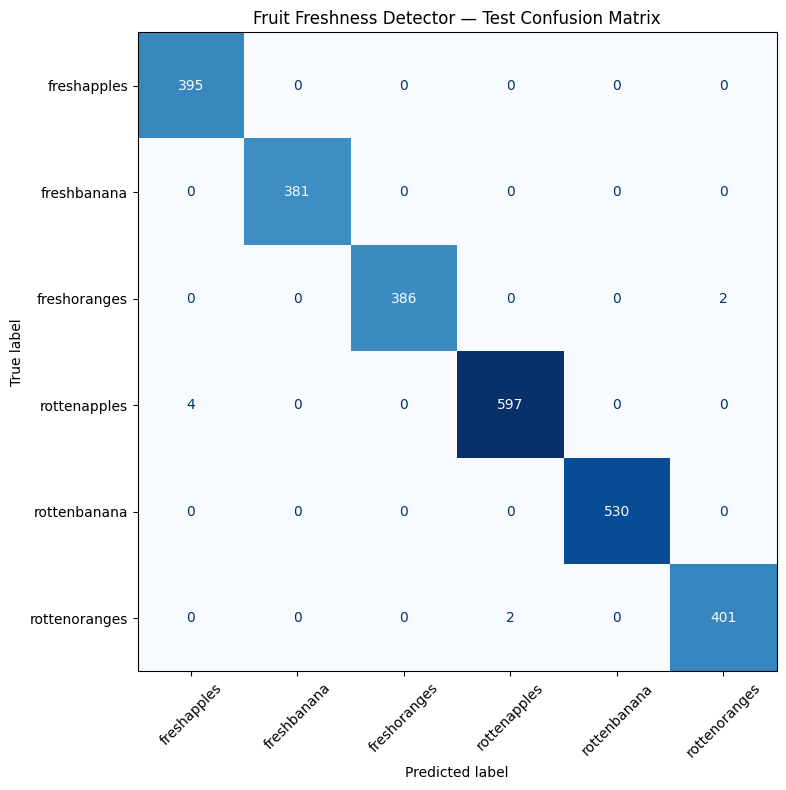

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

ax.set_title("Fruit Freshness Detector — Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
def make_gradcam_heatmap(image_batch, model):
    base = model.get_layer("efficientnetb0")

    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[base.output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(
            image_batch, training=False
        )
        predicted_class = tf.argmax(
            predictions[0]
        )
        class_score = predictions[:, predicted_class]

    grads = tape.gradient(class_score, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads, axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.reduce_max(heatmap) + tf.keras.backend.epsilon()

    return heatmap.numpy(), int(predicted_class.numpy())

In [ ]:
# Get one batch from the test dataset
images, labels = next(iter(test_ds))
image_batch = images[:1]

heatmap, predicted_index = make_gradcam_heatmap(
    image_batch, best_model
)

true_index = int(labels[0].numpy())

print("Actual class:", class_names[true_index])
print("Predicted class:", class_names[predicted_index])

KeyError: "Exception encountered when calling Functional.call().\n\n\x1b[1m132118172780176\x1b[0m\n\nArguments received by Functional.call():\n  • inputs=tf.Tensor(shape=(1, 224, 224, 3), dtype=float32)\n  • training=False\n  • mask=None\n  • kwargs=<class 'inspect._empty'>"

In [ ]:
def make_gradcam_heatmap(image_batch, model):
    base_model = model.get_layer("efficientnetb0")

    # Extract an internal feature map and the EfficientNet output
    feature_extractor = tf.keras.Model(
        inputs=base_model.input,
        outputs=[
            base_model.get_layer("top_conv").output,
            base_model.output
        ]
    )

    with tf.GradientTape() as tape:
        # Follow the same path as the trained model
        x = model.get_layer("data_augmentation")(
            image_batch, training=False
        )

        conv_outputs, base_output = feature_extractor(
            x, training=False
        )
        tape.watch(conv_outputs)

        # Pass EfficientNet output through the trained classifier head
        x = base_output
        base_index = model.layers.index(base_model)

        for layer in model.layers[base_index + 1:]:
            x = layer(x, training=False)

        predictions = x
        predicted_class = tf.argmax(predictions[0])
        class_score = predictions[:, predicted_class]

    grads = tape.gradient(class_score, conv_outputs)

    if grads is None:
        raise ValueError(
            "Grad-CAM gradients could not be calculated."
        )

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads, axis=-1
    )
    heatmap = tf.maximum(heatmap, 0)
    heatmap /= (
        tf.reduce_max(heatmap) +
        tf.keras.backend.epsilon()
    )

    return heatmap.numpy(), int(predicted_class.numpy())

In [ ]:
images, labels = next(iter(test_ds))
image_batch = images[:1]

heatmap, predicted_index = make_gradcam_heatmap(
    image_batch, best_model
)

true_index = int(labels[0].numpy())

print("Actual class:", class_names[true_index])
print("Predicted class:", class_names[predicted_index])

Actual class: freshapples
Predicted class: freshapples


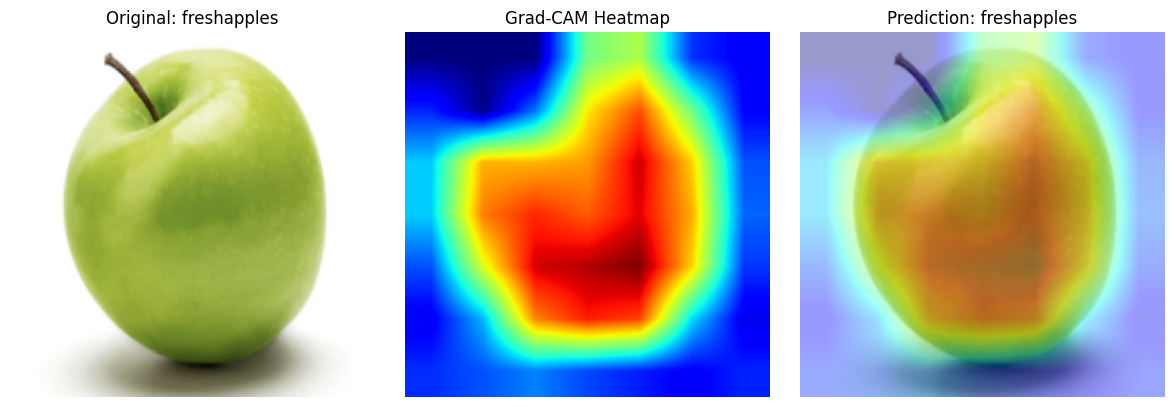

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# Convert the selected image to a displayable format
original_image = tf.cast(image_batch[0], tf.uint8).numpy()

# Resize the heatmap to match the original image
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    (original_image.shape[0], original_image.shape[1])
).numpy().squeeze()

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title(f"Original: {class_names[true_index]}")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(original_image)
plt.imshow(heatmap_resized, cmap="jet", alpha=0.4)
plt.title(f"Prediction: {class_names[predicted_index]}")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import json
import shutil

# Save the final model
FINAL_MODEL_PATH = PROJECT_DIR / "fruit_freshness_model.keras"
best_model.save(str(FINAL_MODEL_PATH))

# Save class names in the same order used during training
CLASS_NAMES_PATH = PROJECT_DIR / "class_names.json"

with open(CLASS_NAMES_PATH, "w") as f:
    json.dump(class_names, f, indent=4)

print("Model saved:", FINAL_MODEL_PATH)
print("Model size (MB):", round(
    FINAL_MODEL_PATH.stat().st_size / (1024 * 1024), 2
))
print("Class names saved:", CLASS_NAMES_PATH)
print("Classes:", class_names)

Model saved: /content/drive/MyDrive/FruitFresh_AI/fruit_freshness_model.keras
Model size (MB): 27.67
Class names saved: /content/drive/MyDrive/FruitFresh_AI/class_names.json
Classes: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']


In [ ]:
from pathlib import Path

print("Model exists:",
      (PROJECT_DIR / "fruit_freshness_model.keras").exists())

print("Class labels exist:",
      (PROJECT_DIR / "class_names.json").exists())

print("Checkpoint files:")
for path in (PROJECT_DIR / "checkpoints").glob("*"):
    print(path.name, f"{path.stat().st_size / (1024 * 1024):.2f} MB")

Model exists: True
Class labels exist: True
Checkpoint files:
best_head.keras 16.35 MB
best_finetuned.keras 27.68 MB


In [ ]:
import tensorflow as tf
import json

MODEL_PATH = PROJECT_DIR / "fruit_freshness_model.keras"
LABELS_PATH = PROJECT_DIR / "class_names.json"

loaded_model = tf.keras.models.load_model(str(MODEL_PATH))

with open(LABELS_PATH, "r") as f:
    saved_classes = json.load(f)

probabilities = loaded_model.predict(image_batch, verbose=0)[0]
predicted_index = int(probabilities.argmax())

print("Reload successful")
print("Predicted class:", saved_classes[predicted_index])
print("Confidence:", f"{probabilities[predicted_index] * 100:.2f}%")
print("Number of classes:", len(saved_classes))

Reload successful
Predicted class: freshapples
Confidence: 99.97%
Number of classes: 6


In [ ]:
from sklearn.metrics import classification_report
from pathlib import Path

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
)

REPORT_PATH = PROJECT_DIR / "evaluation_report.txt"
REPORT_PATH.write_text(report, encoding="utf-8")

print(report)
print("\nSaved report:", REPORT_PATH)

               precision    recall  f1-score   support

  freshapples     0.9900    1.0000    0.9950       395
  freshbanana     1.0000    1.0000    1.0000       381
 freshoranges     1.0000    0.9948    0.9974       388
 rottenapples     0.9967    0.9933    0.9950       601
 rottenbanana     1.0000    1.0000    1.0000       530
rottenoranges     0.9950    0.9950    0.9950       403

     accuracy                         0.9970      2698
    macro avg     0.9969    0.9972    0.9971      2698
 weighted avg     0.9970    0.9970    0.9970      2698


Saved report: /content/drive/MyDrive/FruitFresh_AI/evaluation_report.txt


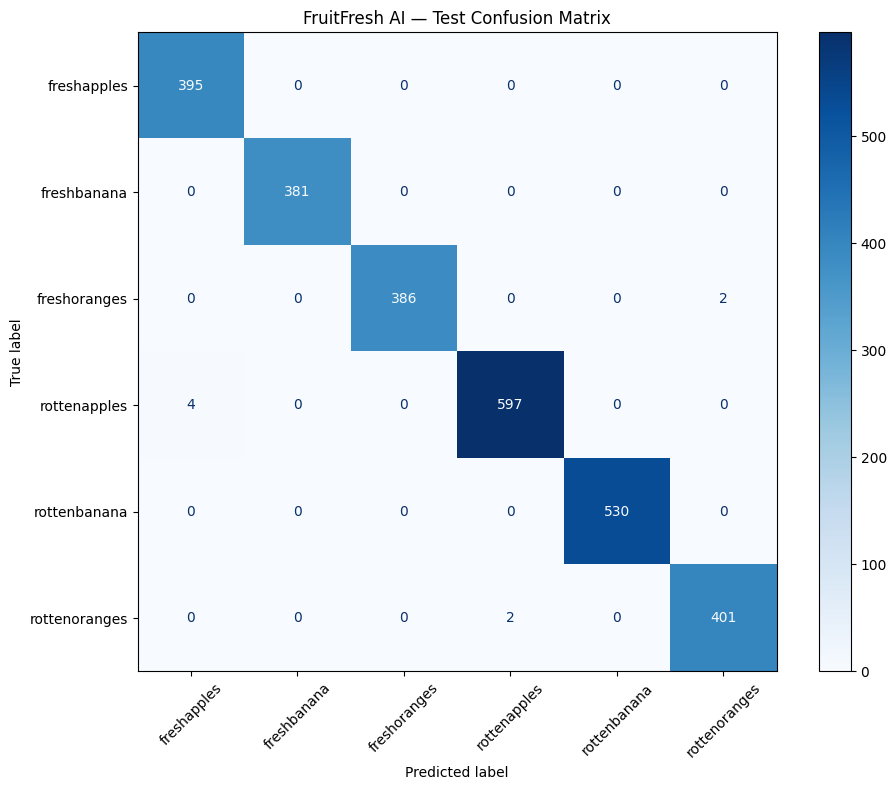

Saved confusion matrix: /content/drive/MyDrive/FruitFresh_AI/confusion_matrix.png


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(10, 8))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(ax=ax, cmap="Blues", xticks_rotation=45)
ax.set_title("FruitFresh AI — Test Confusion Matrix")
fig.tight_layout()

CM_PATH = PROJECT_DIR / "confusion_matrix.png"
fig.savefig(CM_PATH, dpi=200, bbox_inches="tight")
plt.show()

print("Saved confusion matrix:", CM_PATH)

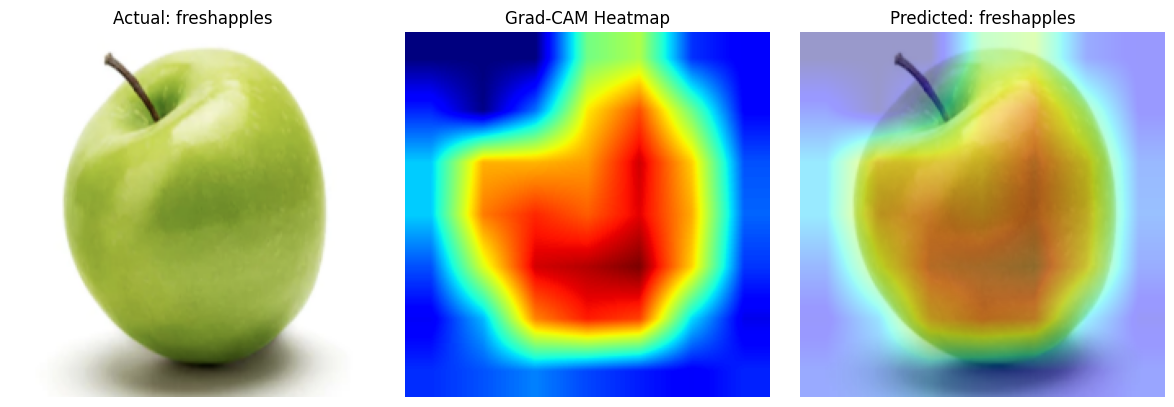


Final project artifacts:
fruit_freshness_model.keras: OK
class_names.json: OK
evaluation_report.txt: OK
confusion_matrix.png: OK
gradcam_example.png: OK


In [ ]:
# Save the visualization from your existing Grad-CAM variables
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(original_image)
axes[0].set_title(f"Actual: {class_names[true_index]}")
axes[0].axis("off")

axes[1].imshow(heatmap_resized, cmap="jet")
axes[1].set_title("Grad-CAM Heatmap")
axes[1].axis("off")

axes[2].imshow(original_image)
axes[2].imshow(heatmap_resized, cmap="jet", alpha=0.4)
axes[2].set_title(f"Predicted: {class_names[predicted_index]}")
axes[2].axis("off")

fig.tight_layout()

GRADCAM_PATH = PROJECT_DIR / "gradcam_example.png"
fig.savefig(GRADCAM_PATH, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print("\nFinal project artifacts:")
for name in [
    "fruit_freshness_model.keras",
    "class_names.json",
    "evaluation_report.txt",
    "confusion_matrix.png",
    "gradcam_example.png",
]:
    path = PROJECT_DIR / name
    print(f"{name}: {'OK' if path.exists() else 'MISSING'}")